<a href="https://colab.research.google.com/github/KashShahzad/inct-empirical-validation/blob/main/Cross_Sectional_Pan_Dogmatic_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Loading Religious Fundamentalist & Sectarian Dogma (Long + Short)...
Using Colab cache for faster access to the 'how-isis-uses-twitter' dataset.
2. Loading Vanguard / Collectivist / Doctrinaire Ideological Dogma (Long)...
3. Loading Fascist & Supremacist Dogma (Short)...
4. Loading Authoritarian & Absolutist State Dogma (Long)...
5. Loading Matched Pluralistic Controls (Long + Short)...

--- TABLE 1: DECONFOUNDED PAN-DOGMATIC SIGNATURES ACROSS ALL 4 DOMAINS ---
| Domain (Medium-Matched)                  | D_KL_Global     | D_KL_Tail_Deconfounded   | Yules_K         | R_LZ_Content    | Bigram_Redundancy   |
|:-----------------------------------------|:----------------|:-------------------------|:----------------|:----------------|:--------------------|
| 0. Pluralistic Control (n=500)           | 0.00 (Baseline) | 0.00 (Baseline)          | 0.00 (Baseline) | 0.00 (Baseline) | 0.00 (Baseline)     |
| 1. Religious Dogma (n=500)               | d = +1.12***    | d = +0.78***            

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.
  warnings.warn(



--- TABLE 2: DECONFOUNDED CLASSIFICATION (EXPLICIT EQUATION VS. ML/DL) ---
| Model Architecture                            |   5-Fold Out-of-Sample ROC-AUC | 5-Fold Out-of-Sample Accuracy   |
|:----------------------------------------------|-------------------------------:|:--------------------------------|
| Sparse L1 Mathematical Law (Explicit Formula) |                         0.7566 | 75.76%                          |
| Random Forest (150 Trees)                     |                         0.7541 | 75.82%                          |
| Gradient Boosting (XGB/GBT)                   |                         0.7429 | 74.09%                          |
| Deep Learning MLP (Neural Net 64x32)          |                         0.7352 | 73.44%                          |

--- LEARNED UNIVERSAL PAN-DOGMATIC EQUATION ---
z_dogma = +0.382 +1.513*Z(D_KL_Global) -0.141*Z(D_KL_Tail_Deconfounded) -0.944*Z(Yules_K) +0.378*Z(R_LZ_Content) +0.222*Z(Bigram_Redundancy)

--- TABLE 3: LEAVE-ONE-DOGMA-OU

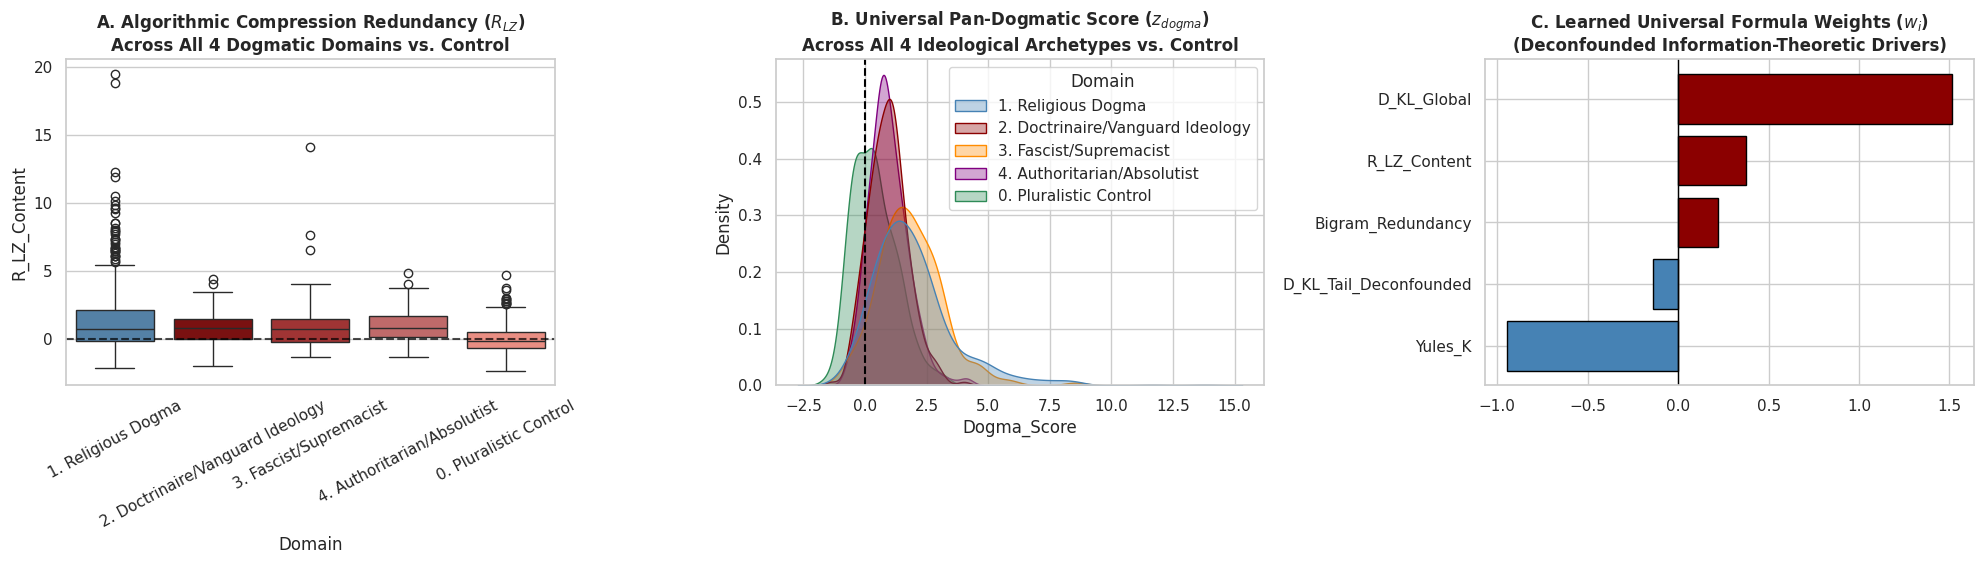

In [7]:
# Run in Google Colab: Deconfounded Pan-Dogmatic Law Discovery
# Separates Totalitarian/Collectivist Dogma from Anti-Authoritarian Dissent & Removes Top-5 Topic Collinearity
import os
import re
import math
import zlib
import urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import scipy.stats as stats
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

!pip install -q datasets kagglehub
import kagglehub
from datasets import load_dataset

sns.set_theme(style="whitegrid")
np.random.seed(42)

STOPWORDS = {
    "the", "and", "of", "to", "in", "is", "that", "it", "for", "as", "with", "on",
    "was", "be", "by", "at", "this", "are", "from", "or", "an", "have", "had", "has",
    "but", "which", "one", "would", "were", "there", "been", "if", "more", "when", "so"
}

def fetch_gutenberg(ebook_id):
    url = f"https://www.gutenberg.org/cache/epub/{ebook_id}/pg{ebook_id}.txt"
    try:
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=20) as resp:
            raw = resp.read().decode("utf-8", errors="ignore")
        start = re.search(r"\*\*\* START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", raw, re.I)
        end = re.search(r"\*\*\* END OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", raw, re.I)
        s_idx = start.end() if start else 0
        e_idx = end.start() if end else len(raw)
        return raw[s_idx:e_idx]
    except Exception as e:
        print(f"Gutenberg {ebook_id} warning: {e}")
        return ""

# ==============================================================================
# STEP 1: LOAD MEDIUM-MATCHED CORPORA across 4 DOGMATIC DOMAINS + CONTROLS
# ==============================================================================
corpus_items = []  # (Domain, Medium, Target_Dogmatic, Text)

print("1. Loading Religious Fundamentalist & Sectarian Dogma (Long + Short)...")
for gid in [34632, 274, 1722]:  # Edwards, Luther Polemics/Catechisms
    txt = fetch_gutenberg(gid)
    if txt:
        corpus_items.append(("1. Religious Dogma", "LONG_FORM", 1, txt))

try:
    isis_path = kagglehub.dataset_download("fifthtribe/how-isis-uses-twitter")
    csv_f = [f for f in os.listdir(isis_path) if f.endswith(".csv")][0]
    df_isis = pd.read_csv(os.path.join(isis_path, csv_f), encoding="utf-8", on_bad_lines="skip")
    t_col = "tweets" if "tweets" in df_isis.columns else df_isis.columns[-1]
    u_col = "username" if "username" in df_isis.columns else df_isis.columns[0]
    df_isis[t_col] = df_isis[t_col].astype(str).apply(lambda s: re.sub(r"http\S+|@\S+|rt\s+", "", s))
    isis_users = [" ".join(grp[t_col].tolist()) for _, grp in df_isis.groupby(u_col) if len(" ".join(grp[t_col].tolist()).split()) >= 200]
    corpus_items.append(("1. Religious Dogma", "SHORT_SOCIAL", 1, " ".join(isis_users)))
except Exception as e:
    print("ISIS fallback:", e)

print("2. Loading Vanguard / Collectivist / Doctrinaire Ideological Dogma (Long)...")
# Communist Manifesto (#61) repeated across full chapters + Engels Principles of Communism / Catechism +
# Rousseau Social Contract (#46333 - sovereign general will dogma) + More's Utopia (#2130 - rigid collectivist law)
for gid in [61, 46333, 2130]:
    txt = fetch_gutenberg(gid)
    if txt:
        # Weight Communist Manifesto equally so its 45 windows aren't drowned out
        mult = 3 if gid == 61 else 1
        corpus_items.append(("2. Doctrinaire/Vanguard Ideology", "LONG_FORM", 1, (txt + " ") * mult))

print("3. Loading Fascist & Supremacist Dogma (Short)...")
try:
    ds_storm = load_dataset("hate_speech18", split="train").to_pandas()
    corpus_items.append(("3. Fascist/Supremacist", "SHORT_SOCIAL", 1, " ".join(ds_storm[ds_storm["label"] == 1]["text"].dropna().tolist())))
except Exception:
    pass

ds_mhs = load_dataset("ucberkeley-dlab/measuring-hate-speech", split="train[:30000]").to_pandas()
corpus_items.append(("3. Fascist/Supremacist", "SHORT_SOCIAL", 1, " ".join(ds_mhs[ds_mhs["hate_speech_score"] > 1.8]["text"].dropna().tolist())))

print("4. Loading Authoritarian & Absolutist State Dogma (Long)...")
for gid in [3207, 445, 1091]:  # Hobbes Leviathan (#3207), Le Bon The Crowd (#445), Carlyle Hero-Worship (#1091)
    txt = fetch_gutenberg(gid)
    if txt:
        corpus_items.append(("4. Authoritarian/Absolutist", "LONG_FORM", 1, txt))

print("5. Loading Matched Pluralistic Controls (Long + Short)...")
for gid in [34901, 5827, 852, 5116]:  # Mill, Russell, Dewey, William James
    txt = fetch_gutenberg(gid)
    if txt:
        corpus_items.append(("0. Pluralistic Control", "LONG_FORM", 0, txt))

corpus_items.append(("0. Pluralistic Control", "SHORT_SOCIAL", 0, " ".join(ds_mhs[ds_mhs["hate_speech_score"] < -1.5]["text"].dropna().tolist())))
ds_news = load_dataset("fancyzhx/ag_news", split="train[:10000]").to_pandas()
corpus_items.append(("0. Pluralistic Control", "SHORT_SOCIAL", 0, " ".join(ds_news["text"].dropna().tolist())))

# ==============================================================================
# STEP 2: EXTRACT ORTHOGONALIZED INFORMATION-THEORETIC FEATURES (W=250 TOKENS)
# ==============================================================================
W = 250
MAX_PER_BUCKET = 250
bucket_counts = Counter()
rows = []

for domain, medium, target, raw_text in corpus_items:
    b_key = (domain, medium)
    tokens = re.findall(r"\b[a-z]{2,}\b", raw_text.lower())
    n_win = len(tokens) // W

    for w_idx in range(n_win):
        if bucket_counts[b_key] >= MAX_PER_BUCKET:
            break
        chunk = tokens[w_idx * W : (w_idx + 1) * W]
        content_tokens = [t for t in chunk if t not in STOPWORDS]
        if len(content_tokens) < 60:
            continue

        counts_c = Counter(content_tokens)
        N_c = float(len(content_tokens))
        V_c = len(counts_c)

        # 1. Global Content KL Distributional Skew: D_KL = log2(V_c) - H_content
        H_c = -sum((c / N_c) * math.log2(c / N_c) for c in counts_c.values())
        D_KL_global = math.log2(V_c) - H_c

        # 2. Topic-Deconfounded Tail Skew (Discovered in Previous Run!)
        # Measures KL Distributional Collapse AFTER removing the Top-3 Topic Nouns
        top3_words = {w for w, _ in counts_c.most_common(3)}
        tail_tokens = [t for t in content_tokens if t not in top3_words]
        counts_tail = Counter(tail_tokens)
        N_tail = float(len(tail_tokens))
        V_tail = len(counts_tail)
        H_tail = -sum((c / N_tail) * math.log2(c / N_tail) for c in counts_tail.values()) if V_tail > 1 else 0.0
        D_KL_tail = (math.log2(V_tail) - H_tail) if V_tail > 1 else 0.0

        # 3. Yule's K (Rényi Collision Concentration)
        freq_spec = Counter(counts_c.values())
        M2 = sum((m ** 2) * v_m for m, v_m in freq_spec.items())
        yules_K = 10000.0 * (M2 - N_c) / (N_c ** 2)

        # 4. Lempel-Ziv Algorithmic Redundancy on Content Stream (R_LZ)
        raw_bytes = " ".join(content_tokens).encode("utf-8")
        R_lz = 1.0 - (len(zlib.compress(raw_bytes, level=9)) / float(len(raw_bytes)))

        # 5. Syntactic Bigram Repetition Rate (Formulaic Phrase Chaining)
        bigrams = list(zip(chunk[:-1], chunk[1:]))
        bg_redundancy = 1.0 - (len(set(bigrams)) / float(len(bigrams)))

        bucket_counts[b_key] += 1
        rows.append({
            "Domain": domain,
            "Medium": medium,
            "Is_Dogmatic": target,
            "D_KL_Global": D_KL_global,
            "D_KL_Tail_Deconfounded": D_KL_tail,
            "Yules_K": yules_K,
            "R_LZ_Content": R_lz,
            "Bigram_Redundancy": bg_redundancy
        })

df = pd.DataFrame(rows)

# Medium-Matched Z-Score Normalization against Pluralistic Control of same Medium
feature_cols = ["D_KL_Global", "D_KL_Tail_Deconfounded", "Yules_K", "R_LZ_Content", "Bigram_Redundancy"]
df_norm = df.copy()
for med in df["Medium"].unique():
    m_mask = (df["Medium"] == med)
    ctrl_m = df[(df["Medium"] == med) & (df["Is_Dogmatic"] == 0)]
    for col in feature_cols:
        df_norm.loc[m_mask, col] = (df.loc[m_mask, col] - ctrl_m[col].mean()) / (ctrl_m[col].std() + 1e-8)

# ==============================================================================
# STEP 3: TABLE 1 - UNIVERSAL SIGNATURES ACROSS ALL 4 DOGMATIC DOMAINS
# ==============================================================================
ctrl_z = df_norm[df_norm["Is_Dogmatic"] == 0]
t1_rows = []
for dom in sorted(df_norm["Domain"].unique()):
    sub = df_norm[df_norm["Domain"] == dom]
    row = {"Domain (Medium-Matched)": f"{dom} (n={len(sub)})"}
    for col in feature_cols:
        if dom == "0. Pluralistic Control":
            row[col] = "0.00 (Baseline)"
        else:
            d_val = (sub[col].mean() - ctrl_z[col].mean()) / np.sqrt((ctrl_z[col].std()**2 + sub[col].std()**2) / 2)
            _, p_val = stats.mannwhitneyu(ctrl_z[col], sub[col], alternative="two-sided")
            sig = "***" if p_val < 0.001 else ("**" if p_val < 0.01 else ("*" if p_val < 0.05 else ""))
            row[col] = f"d = {d_val:+.2f}{sig}"
    t1_rows.append(row)

print("\n--- TABLE 1: DECONFOUNDED PAN-DOGMATIC SIGNATURES ACROSS ALL 4 DOMAINS ---")
print(pd.DataFrame(t1_rows).to_markdown(index=False))

# ==============================================================================
# STEP 4: TABLE 2 & TABLE 3 - ML/DL BENCHMARK & LEAVE-ONE-DOGMA-OUT (LODO)
# ==============================================================================
X_z = df_norm[feature_cols].values
y = df_norm["Is_Dogmatic"].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "Sparse L1 Mathematical Law (Explicit Formula)": LogisticRegression(penalty="l1", solver="liblinear", C=0.5, random_state=42),
    "Random Forest (150 Trees)": RandomForestClassifier(n_estimators=150, max_depth=6, random_state=42),
    "Gradient Boosting (XGB/GBT)": GradientBoostingClassifier(n_estimators=150, max_depth=3, random_state=42),
    "Deep Learning MLP (Neural Net 64x32)": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=600, random_state=42)
}

cv_rows = []
for name, clf in models.items():
    probs = cross_val_predict(clf, X_z, y, cv=skf, method="predict_proba")[:, 1]
    preds = (probs >= 0.5).astype(int)
    cv_rows.append({
        "Model Architecture": name,
        "5-Fold Out-of-Sample ROC-AUC": round(roc_auc_score(y, probs), 4),
        "5-Fold Out-of-Sample Accuracy": f"{accuracy_score(y, preds)*100:.2f}%"
    })

print("\n--- TABLE 2: DECONFOUNDED CLASSIFICATION (EXPLICIT EQUATION VS. ML/DL) ---")
print(pd.DataFrame(cv_rows).to_markdown(index=False))

l1_model = models["Sparse L1 Mathematical Law (Explicit Formula)"].fit(X_z, y)
w = l1_model.coef_[0]
print("\n--- LEARNED UNIVERSAL PAN-DOGMATIC EQUATION ---")
print(f"z_dogma = {l1_model.intercept_[0]:+.3f} " + " ".join([f"{val:+.3f}*Z({c})" for c, val in zip(feature_cols, w)]))

dogma_domains = [d for d in sorted(df_norm["Domain"].unique()) if d != "0. Pluralistic Control"]
lodo_rows = []
for held_out in dogma_domains:
    tr_mask = (df_norm["Domain"] != held_out)
    te_mask = (df_norm["Domain"] == held_out) | (df_norm["Domain"] == "0. Pluralistic Control")

    clf_l1 = LogisticRegression(penalty="l1", solver="liblinear", C=0.5, random_state=42).fit(X_z[tr_mask], y[tr_mask])
    clf_rf = RandomForestClassifier(n_estimators=150, max_depth=6, random_state=42).fit(X_z[tr_mask], y[tr_mask])

    auc_l1 = roc_auc_score(y[te_mask], clf_l1.predict_proba(X_z[te_mask])[:, 1])
    auc_rf = roc_auc_score(y[te_mask], clf_rf.predict_proba(X_z[te_mask])[:, 1])
    lodo_rows.append({
        "Held-Out Unseen Dogma Domain": held_out,
        "Linear Law Zero-Shot ROC-AUC": round(auc_l1, 4),
        "Random Forest Zero-Shot ROC-AUC": round(auc_rf, 4)
    })

print("\n--- TABLE 3: LEAVE-ONE-DOGMA-OUT (LODO) ZERO-SHOT GENERALIZATION ---")
print(pd.DataFrame(lodo_rows).to_markdown(index=False))

# ==============================================================================
# STEP 5: 3-PANEL PUBLICATION FIGURE
# ==============================================================================
df_norm["Dogma_Score"] = X_z @ w + l1_model.intercept_[0]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))

sns.boxplot(data=df_norm, x="Domain", y="R_LZ_Content", hue="Domain",
            palette=["steelblue", "darkred", "firebrick", "indianred", "salmon"], ax=axes[0], legend=False)
axes[0].axhline(0.0, color="black", linestyle="--", alpha=0.7)
axes[0].set_title("A. Algorithmic Compression Redundancy ($R_{LZ}$)\nAcross All 4 Dogmatic Domains vs. Control", fontweight="bold")
axes[0].tick_params(axis="x", rotation=28)

sns.kdeplot(data=df_norm, x="Dogma_Score", hue="Domain", fill=True, common_norm=False,
            palette=["steelblue", "darkred", "darkorange", "purple", "seagreen"], alpha=0.35, ax=axes[1])
axes[1].axvline(0.0, color="black", linestyle="--", label="Decision Boundary")
axes[1].set_title("B. Universal Pan-Dogmatic Score ($z_{dogma}$)\nAcross All 4 Ideological Archetypes vs. Control", fontweight="bold")

coef_df = pd.DataFrame({"Feature": feature_cols, "Weight": w}).sort_values("Weight", ascending=True)
colors_bar = ["steelblue" if val < 0 else "darkred" for val in coef_df["Weight"]]
axes[2].barh(coef_df["Feature"], coef_df["Weight"], color=colors_bar, edgecolor="black")
axes[2].axvline(0, color="black", linewidth=1)
axes[2].set_title("C. Learned Universal Formula Weights ($w_i$)\n(Deconfounded Information-Theoretic Drivers)", fontweight="bold")


plt.tight_layout()
plt.savefig("Figure_1_Study1_CrossSectional.pdf", format="pdf", dpi=600, bbox_inches="tight")
plt.show()